# Дипломный проект: рекомендательная система для интернет-магазина

## Неделя 3. Эксперименты с моделями

**Задача.** Для каждого пользователя выбрать три товара для блока рекомендаций на главной странице. Метрика качества **Precision@3**: доля рекомендованных товаров, которые пользователь купил.

**Содержание**

1. Загрузка данных
2. Схема валидации и метрика
3. Базовые решения
4. Коллаборативная фильтрация по товарам
5. Матричная факторизация (SVD)
6. Модели на факторах: логистическая регрессия и градиентный бустинг
7. Сравнение моделей и итоговое качество на тесте
8. Какие факторы влияют на решение модели
9. Выводы

In [1]:
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import scipy.sparse as sp
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.decomposition import TruncatedSVD
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, normalize

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', 60)

DATA_DIR = Path('.')
RANDOM_STATE = 42
EVENT_TYPES = ['view', 'addtocart', 'transaction']

## 1. Загрузка данных

Загрузка повторяет первый ноутбук. Удаляем полные дубликаты событий, из свойств товаров оставляем категорию, наличие и числовое свойство 790, восстанавливаем дерево категорий.

In [2]:
# Лог событий
events = pd.read_csv(DATA_DIR / 'events.csv')
events = events.drop_duplicates().sort_values('timestamp').reset_index(drop=True)
events['event_dt'] = pd.to_datetime(events['timestamp'], unit='ms')

# Свойства товаров читаем частями и оставляем только нужные свойства
PROP_FILES = [DATA_DIR / 'item_properties_part1.csv', DATA_DIR / 'item_properties_part2.csv']
KEEP_PROPS = ['categoryid', 'available', '790']
PROP_DTYPES = {'timestamp': 'int64', 'itemid': 'int32', 'property': 'str', 'value': 'str'}

kept = []
for f in PROP_FILES:
    for chunk in pd.read_csv(f, chunksize=2_000_000, dtype=PROP_DTYPES):
        kept.append(chunk[chunk['property'].isin(KEEP_PROPS)])
props = pd.concat(kept, ignore_index=True)
props['prop_dt'] = pd.to_datetime(props['timestamp'], unit='ms')
del kept

# Дерево категорий
cat_tree = pd.read_csv(DATA_DIR / 'category_tree.csv')
parent_of = cat_tree.dropna(subset=['parentid']).set_index('categoryid')['parentid'].astype(int).to_dict()

def path_to_root(cat):
    """Возвращает (корневую категорию, глубину) для категории cat."""
    depth, seen = 0, set()
    while cat in parent_of and cat not in seen:
        seen.add(cat)
        cat = parent_of[cat]
        depth += 1
    return cat, depth

cat_feats = cat_tree.copy()
cat_feats[['cat_root', 'cat_depth']] = [path_to_root(c) for c in cat_feats['categoryid']]
cat_feats = cat_feats.rename(columns={'parentid': 'cat_parent'})
cat_feats['cat_parent'] = cat_feats['cat_parent'].fillna(-1).astype(int)

print('Событий:', len(events), '| записей о свойствах:', len(props), '| категорий:', len(cat_feats))

Событий: 2755641 | записей о свойствах: 4082369 | категорий: 1669


## 2. Схема валидации и метрика

Используем разбиение по времени. Тестовый период (последний месяц) откладываем и обращаемся к нему один раз для итоговой оценки. Чтобы выбирать модели и гиперпараметры, внутри обучающего периода выделяем валидационный период той же длины, что и тестовый.

| Период | Даты | Назначение |
|---|---|---|
| Обучение (для этапа подбора) | 3 мая - 17 июля | история и обучающие срезы |
| Валидация | 18 июля - 17 августа | выбор моделей и гиперпараметров |
| Тест | 18 августа - 18 сентября | итоговая оценка |

Метрика считается по всем пользователям, совершившим покупку в оцениваемом периоде. Пользователям без истории рекомендуем три самых продаваемых товара за последние 30 дней.

In [3]:
SPLIT_DT = pd.Timestamp('2015-08-18')
TEST_END = events['event_dt'].max() + pd.Timedelta(seconds=1)
WINDOW = pd.Timedelta(days=31)
VAL_DT = SPLIT_DT - WINDOW

def get_actual(start, end):
    """Покупки периода [start, end): словарь {пользователь: множество купленных товаров}."""
    period = events[(events['event_dt'] >= start) & (events['event_dt'] < end) & (events['event'] == 'transaction')]
    return period.groupby('visitorid')['itemid'].agg(set).to_dict()

def user_scores(recs, actual, default, k=3):
    """Доля удачных рекомендаций для каждого покупателя (в порядке словаря actual)."""
    return np.array([len(set(recs.get(user, default)[:k]) & bought) / k for user, bought in actual.items()])

def top_popular(hist, cutoff, k=3, days=30):
    """Самые продаваемые товары за последние days дней перед cutoff."""
    recent = hist[(hist['event'] == 'transaction') & (hist['event_dt'] >= cutoff - pd.Timedelta(days=days))]
    return recent['itemid'].value_counts().head(k).index.tolist()

def evaluate(recommender, cutoff, end, return_scores=False):
    """Precision@3 рекомендательной функции на периоде [cutoff, end).

    recommender(hist, cutoff, users, default) -> {пользователь: список товаров};
    история hist содержит только события до cutoff.
    """
    hist = events[events['event_dt'] < cutoff]
    actual = get_actual(cutoff, end)
    default = top_popular(hist, cutoff)
    known_users = set(hist['visitorid'])
    users = [u for u in actual if u in known_users]          # покупатели, у которых есть история
    recs = recommender(hist, cutoff, users, default) if recommender is not None else {}
    scores = user_scores(recs, actual, default)
    return scores if return_scores else float(scores.mean())

for name, (start, end) in {'Валидация': (VAL_DT, SPLIT_DT), 'Тест': (SPLIT_DT, TEST_END)}.items():
    actual = get_actual(start, end)
    known_users = set(events.loc[events['event_dt'] < start, 'visitorid'])
    n_warm = sum(u in known_users for u in actual)
    print(f'{name}: покупателей {len(actual)}, из них с историей {n_warm} ({n_warm / len(actual):.1%})')

Валидация: покупателей 2676, из них с историей 360 (13.5%)
Тест: покупателей 2484, из них с историей 350 (14.1%)


## 3. Базовые решения

1. **Популярные товары:** всем пользователям рекомендуются три самых продаваемых товара за последние 30 дней.
2. **Личная история:** пользователю рекомендуются товары, с которыми он взаимодействовал: сначала добавленные в корзину, затем последние просмотренные. Свободные места заполняются популярными товарами.

In [4]:
def fill_with_default(items, default, k=3):
    """Дополняет список рекомендаций популярными товарами до k штук без повторов."""
    out = list(dict.fromkeys(list(items) + list(default)))
    return out[:k]

def rec_personal(hist, cutoff, users, default):
    """Товары из личной истории: сначала из корзины, затем последние просмотренные."""
    h = hist[hist['visitorid'].isin(users)]
    h = (h.assign(in_cart=(h['event'] == 'addtocart').astype(int))
          .groupby(['visitorid', 'itemid']).agg(in_cart=('in_cart', 'max'), last_dt=('event_dt', 'max'))
          .reset_index()
          .sort_values(['visitorid', 'in_cart', 'last_dt'], ascending=[True, False, False]))
    return {user: fill_with_default(items.tolist()[:3], default) for user, items in h.groupby('visitorid')['itemid']}

results = {}      # {модель: {'val': ..., 'test': ...}}

def add_result(name, recommender):
    results[name] = {'val': evaluate(recommender, VAL_DT, SPLIT_DT),
                     'test': evaluate(recommender, SPLIT_DT, TEST_END)}
    print(f'{name}: валидация {results[name]["val"]:.5f}, тест {results[name]["test"]:.5f}')

add_result('Популярные товары', None)
add_result('Личная история', rec_personal)

Популярные товары: валидация 0.01109, тест 0.00993
Личная история: валидация 0.01881, тест 0.01919


## 4. Коллаборативная фильтрация по товарам

Товары похожи, если с ними взаимодействуют одни и те же пользователи. Строим матрицу «пользователь-товар» с весами событий (просмотр: 1, корзина: 3, покупка: 5), считаем косинусную близость товаров и для пользователя суммируем близости кандидатов к товарам из его истории.

Особенности реализации:

- при расчёте близости не учитываются пользователи с одним товаром и с более чем 100 товарами.
- параметр `own_weight` задаёт, насколько сильно товары из собственной истории пользователя поднимаются в ранжировании; вариант `exclude_seen=True` рекомендует только новые для пользователя товары.

In [5]:
EVENT_WEIGHTS = {'view': 1.0, 'addtocart': 3.0, 'transaction': 5.0}

def build_matrix(hist):
    """Разреженная матрица «пользователь–товар» с максимальным весом события по паре."""
    w = hist.assign(w=hist['event'].map(EVENT_WEIGHTS)).groupby(['visitorid', 'itemid'])['w'].max().reset_index()
    users = pd.Categorical(w['visitorid'])
    items = pd.Categorical(w['itemid'])
    matrix = sp.csr_matrix((w['w'].to_numpy(dtype=np.float32), (users.codes, items.codes)),
                           shape=(len(users.categories), len(items.categories)))
    user_index = {u: i for i, u in enumerate(users.categories)}
    return matrix, user_index, np.asarray(items.categories)

def top_items(scores, item_ids, k=3):
    """Товары с наибольшей положительной оценкой."""
    idx = np.argpartition(-scores, k)[:k]
    idx = idx[np.argsort(-scores[idx])]
    return [item_ids[i] for i in idx if scores[i] > 0]

def make_rec_item_cf(own_weight=1.0, exclude_seen=False, max_items=100):
    def recommender(hist, cutoff, users, default):
        matrix, user_index, item_ids = build_matrix(hist)
        n_items = np.diff(matrix.indptr)
        base = matrix[(n_items >= 2) & (n_items <= max_items)]
        base = normalize(base, axis=0)                      # столбцы-товары единичной длины
        target = matrix[[user_index[u] for u in users]]
        # оценка = история пользователя x матрица косинусных близостей товаров
        scores = ((target @ base.T) @ base).tocsr()
        recs = {}
        for row, user in enumerate(users):
            s = scores[row].toarray().ravel()
            own = target[row]
            if exclude_seen:
                s[own.indices] = 0
            else:
                s[own.indices] += own_weight * own.data
            recs[user] = fill_with_default(top_items(s, item_ids), default)
        return recs
    return recommender

add_result('Item-based CF (own_weight=0)', make_rec_item_cf(own_weight=0.0))
add_result('Item-based CF (own_weight=1)', make_rec_item_cf(own_weight=1.0))
add_result('Item-based CF (только новые товары)', make_rec_item_cf(exclude_seen=True))

Item-based CF (own_weight=0): валидация 0.01682, тест 0.01610
Item-based CF (own_weight=1): валидация 0.01769, тест 0.01664
Item-based CF (только новые товары): валидация 0.00922, тест 0.00832


## 5. Матричная факторизация (SVD)

Матрица «пользователь-товар» раскладывается в произведение матриц меньшего ранга: каждый пользователь и каждый товар описываются вектором скрытых признаков, а оценка пары это скалярное произведение векторов. Используем усечённое сингулярное разложение (`TruncatedSVD`), которое работает с разреженными матрицами.

In [6]:
def make_rec_svd(n_components=64, exclude_seen=False):
    def recommender(hist, cutoff, users, default):
        matrix, user_index, item_ids = build_matrix(hist)
        svd = TruncatedSVD(n_components=n_components, n_iter=5, random_state=RANDOM_STATE)
        svd.fit(matrix)
        recs = {}
        for user in users:
            row = matrix[user_index[user]]
            s = (svd.transform(row) @ svd.components_).ravel()
            if exclude_seen:
                s[row.indices] = 0
            recs[user] = fill_with_default(top_items(s, item_ids), default)
        return recs
    return recommender

add_result('SVD (32 компоненты)', make_rec_svd(32))
add_result('SVD (64 компоненты)', make_rec_svd(64))

SVD (32 компоненты): валидация 0.01096, тест 0.00953
SVD (64 компоненты): валидация 0.01146, тест 0.00993


## 6. Модели на факторах: логистическая регрессия и градиентный бустинг

Задача ставится как бинарная классификация пар «пользователь-товар»: купит ли пользователь товар в течение следующего 31 дня. Кандидаты для пользователя это товары из его истории. Модель оценивает вероятность покупки каждого кандидата, в рекомендации попадают три товара с наибольшей оценкой, свободные места заполняются популярными товарами.

### 6.1. Генерация факторов

Функции те же, что в первом ноутбуке; добавлены четыре фактора пары «пользователь–товар»: число дней с взаимодействием, признак «в корзине, но не куплен», место товара в истории пользователя по давности и доля просмотров товара среди всех просмотров пользователя. Все факторы считаются только по событиям до границы `cutoff`.

In [7]:
def count_events(df, keys, prefix):
    """Число просмотров, корзин и покупок в разрезе keys."""
    out = (df.groupby(keys + ['event']).size().unstack(fill_value=0)
             .reindex(columns=EVENT_TYPES, fill_value=0))
    out.columns = [f'{prefix}_views', f'{prefix}_carts', f'{prefix}_trans']
    return out.astype('int32')

def days_between(later, earlier):
    return ((later - earlier).dt.total_seconds() / 86400).astype('float32')

def property_asof(props, name, cutoff):
    """Последнее значение свойства name для каждого товара, записанное до cutoff."""
    p = props[(props['property'] == name) & (props['prop_dt'] < cutoff)].sort_values('timestamp')
    return p.groupby('itemid')['value'].last()

def build_item_features(ev, cutoff, props, cat_feats):
    """Факторы товара по истории ev (только события до cutoff)."""
    f = count_events(ev, ['itemid'], 'item')
    f['item_users'] = ev.groupby('itemid')['visitorid'].nunique().astype('int32')
    f['item_cart_rate'] = (f['item_carts'] / (f['item_views'] + 1)).astype('float32')
    f['item_buy_rate'] = (f['item_trans'] / (f['item_views'] + 1)).astype('float32')
    for days in (7, 30):
        recent = ev[ev['event_dt'] >= cutoff - pd.Timedelta(days=days)]
        f = f.join(count_events(recent, ['itemid'], f'item_{days}d'), how='left')
    f = f.fillna(0)
    g = ev.groupby('itemid')['event_dt']
    f['item_days_since_last'] = days_between(cutoff, g.max())
    f['item_days_since_first'] = days_between(cutoff, g.min())
    f['categoryid'] = pd.to_numeric(property_asof(props, 'categoryid', cutoff), errors='coerce')
    f['item_available'] = pd.to_numeric(property_asof(props, 'available', cutoff), errors='coerce')
    p790 = property_asof(props, '790', cutoff)
    f['item_prop_790_log'] = np.log1p(pd.to_numeric(p790.str[1:], errors='coerce')).astype('float32')
    f = f.reset_index().merge(cat_feats, on='categoryid', how='left')
    cat_pop = f.groupby('categoryid')[['item_views', 'item_trans']].sum()
    cat_pop.columns = ['cat_views', 'cat_trans']
    f = f.merge(cat_pop.reset_index(), on='categoryid', how='left')
    f['cat_items'] = f.groupby('categoryid')['itemid'].transform('count')
    return f

def build_user_features(ev, cutoff):
    """Факторы пользователя по истории ev (только события до cutoff)."""
    f = count_events(ev, ['visitorid'], 'user')
    f['user_items'] = ev.groupby('visitorid')['itemid'].nunique().astype('int32')
    days = ev.assign(day=ev['event_dt'].dt.normalize()).drop_duplicates(['visitorid', 'day'])
    f['user_active_days'] = days.groupby('visitorid').size().astype('int32')
    f['user_cart_rate'] = (f['user_carts'] / (f['user_views'] + 1)).astype('float32')
    f['user_buy_rate'] = (f['user_trans'] / (f['user_views'] + 1)).astype('float32')
    g = ev.groupby('visitorid')['event_dt']
    f['user_days_since_last'] = days_between(cutoff, g.max())
    f['user_days_since_first'] = days_between(cutoff, g.min())
    return f.reset_index()

def build_user_item_features(ev, cutoff, item_cat):
    """Факторы пары «пользователь–товар» и пары «пользователь–категория»."""
    ui = count_events(ev, ['visitorid', 'itemid'], 'ui')
    g = ev.groupby(['visitorid', 'itemid'])['event_dt']
    ui['ui_days_since_last'] = days_between(cutoff, g.max())
    ui['ui_days_since_first'] = days_between(cutoff, g.min())
    days = ev.assign(day=ev['event_dt'].dt.normalize()).drop_duplicates(['visitorid', 'itemid', 'day'])
    ui['ui_active_days'] = days.groupby(['visitorid', 'itemid']).size().astype('int32')
    ui['ui_cart_no_buy'] = ((ui['ui_carts'] > 0) & (ui['ui_trans'] == 0)).astype('int8')
    ui = ui.reset_index()
    # место товара в истории пользователя: 1 — товар, с которым он взаимодействовал последним
    ui['ui_recency_rank'] = ui.groupby('visitorid')['ui_days_since_last'].rank(method='first').astype('float32')

    ev_cat = ev[['visitorid', 'itemid', 'event']].merge(item_cat, on='itemid', how='inner')
    uc = count_events(ev_cat, ['visitorid', 'categoryid'], 'uc').reset_index()
    return ui, uc

def build_features(ev, cutoff, props, cat_feats):
    """Считает все группы факторов по событиям строго до cutoff."""
    ev = ev[ev['event_dt'] < cutoff]
    item_f = build_item_features(ev, cutoff, props, cat_feats)
    user_f = build_user_features(ev, cutoff)
    item_cat = item_f[['itemid', 'categoryid']].dropna()
    ui_f, uc_f = build_user_item_features(ev, cutoff, item_cat)
    return {'item': item_f, 'user': user_f, 'user_item': ui_f, 'user_category': uc_f}

def assemble_dataset(pairs, feats):
    """Собирает таблицу факторов для заданных пар «пользователь–товар»."""
    df = (pairs.merge(feats['user_item'], on=['visitorid', 'itemid'], how='left')
               .merge(feats['user'], on='visitorid', how='left')
               .merge(feats['item'], on='itemid', how='left')
               .merge(feats['user_category'], on=['visitorid', 'categoryid'], how='left'))
    count_cols = [c for c in df.columns if c.startswith(('ui_', 'uc_')) and 'days' not in c]
    df[count_cols] = df[count_cols].fillna(0)
    df['ui_views_share'] = (df['ui_views'] / (df['user_views'] + 1)).astype('float32')
    return df

### 6.2. Обучающие срезы

На одном срезе положительных примеров мало (около 150 купленных пар), поэтому обучающая выборка собирается из нескольких временных срезов с шагом в неделю. Для каждого среза с границей `cutoff`:

- факторы считаются по событиям до `cutoff`;
- целевая переменная — купил ли пользователь товар в период `[cutoff, cutoff + 31 день)`;
- оставляются все положительные примеры и случайные 20 % отрицательных.

Чтобы не было утечки, для этапа подбора используются только срезы, целевой период которых заканчивается до начала валидации. Для итоговой модели добавляются срезы, целевой период которых заканчивается до начала теста.

In [ ]:
def make_dataset(cutoff, users=None, neg_frac=None):
    """Таблица факторов и целевой переменной для среза с границей cutoff.

    users    - если задано, кандидаты берутся только для этих пользователей;
    neg_frac - доля отрицательных примеров, которую нужно оставить (None — все).
    """
    hist = events[events['event_dt'] < cutoff]
    candidates = hist[['visitorid', 'itemid']].drop_duplicates()
    if users is not None:
        candidates = candidates[candidates['visitorid'].isin(users)]
    future = events[(events['event_dt'] >= cutoff) & (events['event_dt'] < cutoff + WINDOW)
                    & (events['event'] == 'transaction')]
    target = future[['visitorid', 'itemid']].drop_duplicates().assign(target=1)
    candidates = candidates.merge(target, on=['visitorid', 'itemid'], how='left')
    candidates['target'] = candidates['target'].fillna(0).astype('int8')
    if neg_frac is not None:
        negatives = candidates[candidates['target'] == 0].sample(frac=neg_frac, random_state=RANDOM_STATE)
        candidates = pd.concat([candidates[candidates['target'] == 1], negatives], ignore_index=True)
    feats = build_features(events, cutoff, props, cat_feats)
    return assemble_dataset(candidates, feats)

FIRST_CUTOFF = pd.Timestamp('2015-05-23')                       # до этой даты накоплено 20 дней истории
train_cutoffs = [FIRST_CUTOFF + pd.Timedelta(days=7 * i) for i in range(9)]
assert train_cutoffs[-1] + WINDOW <= SPLIT_DT                    # целевые периоды не заходят в тест

start = time.time()
train_slices = {}
for cutoff in train_cutoffs:
    train_slices[cutoff] = make_dataset(cutoff, neg_frac=0.2)
    print(f'Срез {cutoff.date()}: строк {len(train_slices[cutoff]):>7}, '
          f'положительных {train_slices[cutoff]["target"].sum():>4}')

# Таблицы для оценки: кандидаты покупателей валидационного и тестового периодов
eval_sets = {VAL_DT: make_dataset(VAL_DT, users=set(get_actual(VAL_DT, SPLIT_DT))),
             SPLIT_DT: make_dataset(SPLIT_DT, users=set(get_actual(SPLIT_DT, TEST_END)))}
print(f'Время расчёта: {time.time() - start:.0f} с')

Срез 2015-05-23: строк   64833, положительных  144
Срез 2015-05-30: строк   86995, положительных  143
Срез 2015-06-06: строк  109422, положительных  138
Срез 2015-06-13: строк  130704, положительных  125
Срез 2015-06-20: строк  152165, положительных  153
Срез 2015-06-27: строк  173437, положительных  151
Срез 2015-07-04: строк  195004, положительных  178
Срез 2015-07-11: строк  218424, положительных  163
Срез 2015-07-18: строк  244167, положительных  174
Время расчёта: 61 с


In [9]:
val_cutoffs = [c for c in train_cutoffs if c + WINDOW <= VAL_DT]     # срезы для этапа подбора
train_val = pd.concat([train_slices[c] for c in val_cutoffs], ignore_index=True)
train_full = pd.concat(list(train_slices.values()), ignore_index=True)

NOT_FEATURES = ['visitorid', 'itemid', 'target', 'categoryid', 'cat_parent', 'cat_root']
feature_cols = [c for c in train_full.columns if c not in NOT_FEATURES]

print('Срезов для подбора:', len(val_cutoffs), '| строк:', len(train_val), '| положительных:', train_val['target'].sum())
print('Срезов для итоговой модели:', len(train_slices), '| строк:', len(train_full), '| положительных:', train_full['target'].sum())
print('Число факторов:', len(feature_cols))

Срезов для подбора: 4 | строк: 391954 | положительных: 550
Срезов для итоговой модели: 9 | строк: 1375151 | положительных: 1369
Число факторов: 41


### 6.3. Подбор гиперпараметров на валидации

Идентификаторы категорий в модель не подаются: это номинальные признаки с большим числом значений, вместо них используются счётчики по категории.

- **Логистическая регрессия**: пропуски заполняются медианой, признаки стандартизуются; подбирается сила регуляризации `C`.
- **Градиентный бустинг** (`HistGradientBoostingClassifier` из scikit-learn это аналог XGBoost/LightGBM, работает с пропусками напрямую): подбираются число деревьев, скорость обучения, размер дерева и регуляризация.

In [10]:
def make_logreg(C):
    return make_pipeline(SimpleImputer(strategy='median'), StandardScaler(),
                         LogisticRegression(C=C, max_iter=1000))

def make_gb(**params):
    return HistGradientBoostingClassifier(early_stopping=False, random_state=RANDOM_STATE, **params)

def make_rec_model(model):
    """Рекомендации по оценкам обученной модели: три кандидата с наибольшей вероятностью покупки."""
    def recommender(hist, cutoff, users, default):
        data = eval_sets[cutoff]
        scored = data[['visitorid', 'itemid']].assign(score=model.predict_proba(data[feature_cols])[:, 1])
        scored = scored.sort_values(['visitorid', 'score'], ascending=[True, False])
        return {user: fill_with_default(items.tolist()[:3], default)
                for user, items in scored.groupby('visitorid')['itemid']}
    return recommender

candidates_grid = {}
for C in (0.01, 0.1, 1.0):
    candidates_grid[f'Логистическая регрессия (C={C})'] = lambda C=C: make_logreg(C)
gb_grid = [
    dict(max_iter=100, learning_rate=0.05, max_leaf_nodes=7, min_samples_leaf=100),
    dict(max_iter=200, learning_rate=0.05, max_leaf_nodes=7, min_samples_leaf=100, l2_regularization=1.0),
    dict(max_iter=300, learning_rate=0.03, max_leaf_nodes=15, min_samples_leaf=50),
    dict(max_iter=200, learning_rate=0.1, max_leaf_nodes=31, min_samples_leaf=20),
]
for i, params in enumerate(gb_grid, start=1):
    candidates_grid[f'Градиентный бустинг №{i}'] = lambda params=params: make_gb(**params)

tuning = []
for name, factory in candidates_grid.items():
    model = factory().fit(train_val[feature_cols], train_val['target'])
    tuning.append({'Модель': name, 'Precision@3 на валидации': evaluate(make_rec_model(model), VAL_DT, SPLIT_DT)})
tuning = pd.DataFrame(tuning).set_index('Модель')

print('Параметры вариантов градиентного бустинга:')
for i, params in enumerate(gb_grid, start=1):
    print(f'  №{i}: {params}')
tuning.round(5)

Параметры вариантов градиентного бустинга:
  №1: {'max_iter': 100, 'learning_rate': 0.05, 'max_leaf_nodes': 7, 'min_samples_leaf': 100}
  №2: {'max_iter': 200, 'learning_rate': 0.05, 'max_leaf_nodes': 7, 'min_samples_leaf': 100, 'l2_regularization': 1.0}
  №3: {'max_iter': 300, 'learning_rate': 0.03, 'max_leaf_nodes': 15, 'min_samples_leaf': 50}
  №4: {'max_iter': 200, 'learning_rate': 0.1, 'max_leaf_nodes': 31, 'min_samples_leaf': 20}


,Precision@3 на валидации
Модель,
Логистическая регрессия (C=0.01),0.02030
Логистическая регрессия (C=0.1),0.01993
Логистическая регрессия (C=1.0),0.01968
Градиентный бустинг №1,0.01856
Градиентный бустинг №2,0.01981
Градиентный бустинг №3,0.01868
Градиентный бустинг №4,0.01744


In [11]:
# Лучшие варианты каждого семейства переобучаем на всех срезах и оцениваем на тесте
best_models = {}
for family in ('Логистическая регрессия', 'Градиентный бустинг'):
    family_scores = tuning[tuning.index.str.startswith(family)]['Precision@3 на валидации']
    best_name = family_scores.idxmax()
    final_model = candidates_grid[best_name]().fit(train_full[feature_cols], train_full['target'])
    best_models[best_name] = final_model
    results[best_name] = {'val': family_scores.max(),
                          'test': evaluate(make_rec_model(final_model), SPLIT_DT, TEST_END)}
    print(f'{best_name}: валидация {results[best_name]["val"]:.5f}, тест {results[best_name]["test"]:.5f}')

Логистическая регрессия (C=0.01): валидация 0.02030, тест 0.01986
Градиентный бустинг №2: валидация 0.01981, тест 0.01946


## 7. Сравнение моделей и итоговое качество на тесте

Лучшая модель выбирается по валидации; качество на тесте - её итоговая независимая оценка.

Лучшая модель по валидации: Логистическая регрессия (C=0.01)


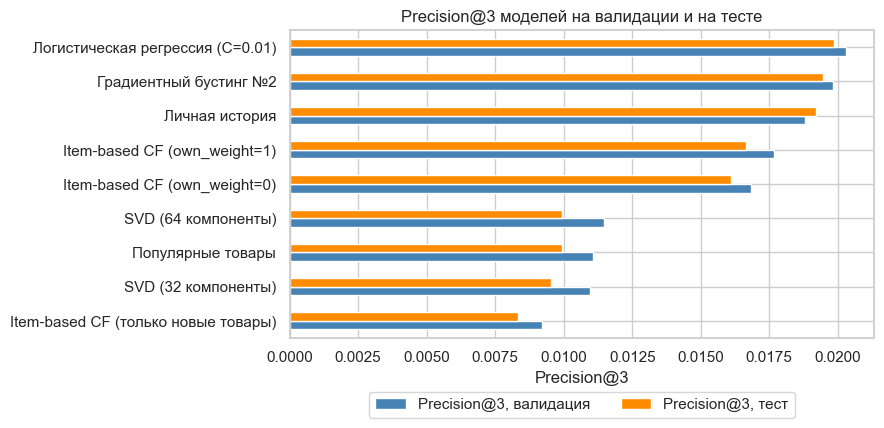

,"Precision@3, валидация","Precision@3, тест"
Логистическая регрессия (C=0.01),0.02030,0.01986
Градиентный бустинг №2,0.01981,0.01946
Личная история,0.01881,0.01919
Item-based CF (own_weight=1),0.01769,0.01664
Item-based CF (own_weight=0),0.01682,0.01610
SVD (64 компоненты),0.01146,0.00993
Популярные товары,0.01109,0.00993
SVD (32 компоненты),0.01096,0.00953
Item-based CF (только новые товары),0.00922,0.00832


In [12]:
summary = pd.DataFrame(results).T.rename(columns={'val': 'Precision@3, валидация', 'test': 'Precision@3, тест'})
summary = summary.sort_values('Precision@3, валидация', ascending=False)
best_name = summary.index[0]
print('Лучшая модель по валидации:', best_name)

fig, ax = plt.subplots(figsize=(9, 4.5))
summary.iloc[::-1].plot(kind='barh', ax=ax, color=['steelblue', 'darkorange'])
ax.set_title('Precision@3 моделей на валидации и на тесте')
ax.set_xlabel('Precision@3')
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.15), ncol=2)
plt.tight_layout(); plt.show()
summary.round(5)

Покупателей в тестовом периоде немного, поэтому различия между моделями нужно проверять на статистическую значимость. Оценим доверительные интервалы бутстрепом по пользователям: многократно выбираем покупателей с возвращением и пересчитываем метрику.

In [13]:
def bootstrap_ci(scores, n_iter=2000, seed=RANDOM_STATE):
    """95 %-й доверительный интервал среднего по бутстреп-выборкам пользователей."""
    rng = np.random.default_rng(seed)
    idx = rng.integers(0, len(scores), size=(n_iter, len(scores)))
    means = scores[idx].mean(axis=1)
    return np.percentile(means, [2.5, 97.5])

best_recommender = make_rec_model(best_models[best_name]) if best_name in best_models else None
test_scores = {
    'Популярные товары': evaluate(None, SPLIT_DT, TEST_END, return_scores=True),
    'Личная история': evaluate(rec_personal, SPLIT_DT, TEST_END, return_scores=True),
}
if best_recommender is not None:
    test_scores[best_name] = evaluate(best_recommender, SPLIT_DT, TEST_END, return_scores=True)

rows = []
for name, scores in test_scores.items():
    low, high = bootstrap_ci(scores)
    rows.append({'Модель': name, 'Precision@3, тест': scores.mean(), '95 % ДИ, нижняя': low, '95 % ДИ, верхняя': high,
                 'Удачных рекомендаций': int(round(scores.sum() * 3))})
ci_table = pd.DataFrame(rows).set_index('Модель')

if best_recommender is not None:
    for baseline in ('Популярные товары', 'Личная история'):
        low, high = bootstrap_ci(test_scores[best_name] - test_scores[baseline])
        print(f'Разность «{best_name}» − «{baseline}»: 95 % ДИ [{low:+.5f}; {high:+.5f}]')
ci_table.round(5)

Разность «Логистическая регрессия (C=0.01)» − «Популярные товары»: 95 % ДИ [+0.00765; +0.01248]
Разность «Логистическая регрессия (C=0.01)» − «Личная история»: 95 % ДИ [-0.00094; +0.00215]


,"Precision@3, тест","95 % ДИ, нижняя","95 % ДИ, верхняя",Удачных рекомендаций
Модель,,,,
Популярные товары,0.00993,0.00778,0.01235,74
Личная история,0.01919,0.01583,0.02254,143
Логистическая регрессия (C=0.01),0.01986,0.01677,0.02348,148


In [14]:
# Качество отдельно для покупателей с историей и без неё
actual_test = get_actual(SPLIT_DT, TEST_END)
known_users = set(events.loc[events['event_dt'] < SPLIT_DT, 'visitorid'])
is_warm = np.array([u in known_users for u in actual_test])

segments = pd.DataFrame({name: {'С историей': scores[is_warm].mean(), 'Без истории': scores[~is_warm].mean()}
                         for name, scores in test_scores.items()}).T
segments['Покупателей с историей'] = is_warm.sum()
segments['Покупателей без истории'] = (~is_warm).sum()
segments.round(5)

,С историей,Без истории,Покупателей с историей,Покупателей без истории
Популярные товары,0.01714,0.00875,350,2134
Личная история,0.08286,0.00875,350,2134
Логистическая регрессия (C=0.01),0.08762,0.00875,350,2134


## 8. Какие факторы влияют на решение модели

Используем перестановочную важность: значения одного фактора перемешиваются, и измеряется, насколько падает качество ранжирования кандидатов (ROC AUC) на тестовой таблице. Чем сильнее падение, тем важнее фактор для модели.

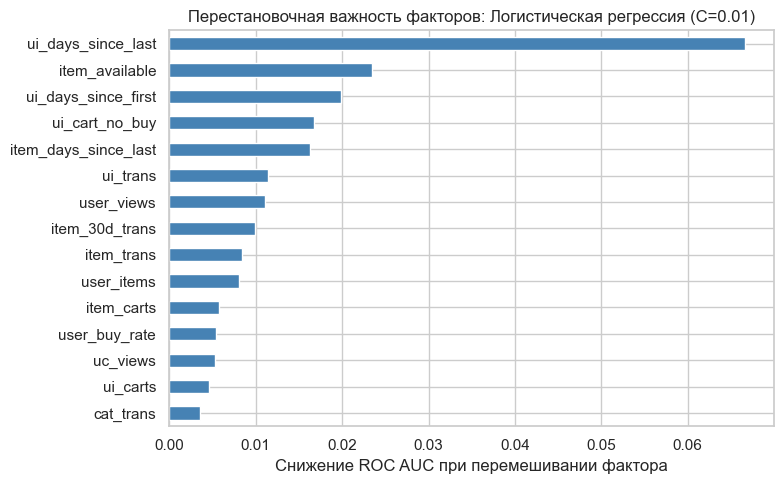

,Важность
ui_days_since_last,0.0666
item_available,0.0234
ui_days_since_first,0.0199
ui_cart_no_buy,0.0168
item_days_since_last,0.0163
ui_trans,0.0114
user_views,0.0110
item_30d_trans,0.0099
item_trans,0.0084
user_items,0.0080


In [15]:
explain_name = best_name if best_name in best_models else list(best_models)[-1]
explain_model = best_models[explain_name]
test_set = eval_sets[SPLIT_DT]

importance = permutation_importance(explain_model, test_set[feature_cols], test_set['target'],
                                    scoring='roc_auc', n_repeats=5, random_state=RANDOM_STATE)
importance = pd.Series(importance.importances_mean, index=feature_cols).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(8, 5))
importance.head(15).iloc[::-1].plot(kind='barh', ax=ax, color='steelblue')
ax.set_title(f'Перестановочная важность факторов: {explain_name}')
ax.set_xlabel('Снижение ROC AUC при перемешивании фактора')
plt.tight_layout(); plt.show()
importance.head(15).round(4).to_frame('Важность')

## 9. Выводы

**Результаты экспериментов** (Precision@3 на тесте, 2484 покупателя):

| Модель | Валидация | Тест |
|---|---|---|
| Логистическая регрессия на факторах (C=0.01) | 0.0203 | 0.0199 |
| Градиентный бустинг на факторах | 0.0198 | 0.0195 |
| Личная история (правило) | 0.0188 | 0.0192 |
| Коллаборативная фильтрация по товарам | 0.0177 | 0.0166 |
| Матричная факторизация SVD | 0.0115 | 0.0099 |
| Популярные товары | 0.0111 | 0.0099 |

**Что из этого следует**

- Лучшая модель по валидации это **логистическая регрессия на построенных факторах**. Она ранжирует товары из истории пользователя по вероятности покупки, свободные места заполняются популярными товарами. На тесте Precision@3 = 0.0199, это вдвое выше, чем у рекомендации популярных товаров (0.0099), и разница статистически значима.
- Преимущество моделей на факторах перед простым правилом «личная история» невелико (148 удачных рекомендаций против 143) и статистически не значимо: доверительный интервал разности включает ноль. Градиентный бустинг не дал прироста относительно линейной модели: положительных примеров мало (около 1400 на все срезы), и более сложная модель не находит устойчивых закономерностей.
- Коллаборативная фильтрация и SVD уступают личной истории. Рекомендация только новых для пользователя товаров работает хуже популярных: в этих данных пользователи чаще покупают то, что уже смотрели или клали в корзину.
- Главное ограничение это **холодный старт**: только 14 % покупателей тестового периода имеют историю. Для покупателей с историей точность модели составляет 0.088 (в пять раз выше, чем у популярных товаров 0.017), для остальных доступны только популярные товары (0.009). Поэтому общее значение метрики низкое при любой модели.

**Факторы, которые сильнее всего влияют на решение модели:** давность последнего и первого взаимодействия пользователя с товаром, наличие товара, признак «товар в корзине, но не куплен» и давность последнего события с товаром.

**Что можно улучшить**

- Учитывать действия пользователя в текущей сессии (рекомендации в реальном времени): это единственный способ персонализировать выдачу для новых посетителей.
- Расширить список кандидатов товарами из тех же категорий и проверить влияние на метрику.
- Провести A/B-тест: офлайн-метрика считается по покупкам, совершённым без блока рекомендаций, и не показывает, как сам блок повлияет на допродажи.